# Maia-2 vs. my validation games

Scores **off-the-shelf Maia-2 (rapid)** on the **validation** games from my chess.com rapid history (`whopizza1`), using the frozen split in `data/splits/whopizza1_rapid.csv`.

- **Why val and not test:** val is where I'm allowed to look and make choices, like which Elo to feed Maia (roadmap §4, decision 2). The test games stay untouched until row G in `docs/results.md` is scored for real.
- **Metrics (roadmap §8):** top-1 / top-3 / top-5 on all of my moves (headline), the same with my first 8 moves removed, and split by phase.
- **Rows** are positions where it was my turn, and the label is the move I actually played.

In [1]:
from datetime import date
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repo root = the folder holding pyproject.toml, so paths work wherever Jupyter starts.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(REPO / "src"))  # import chesspred straight from src/
from chesspred.data.split import add_split_column

POSITIONS  = REPO / "data/processed/chesscom_whopizza1_2026-11-06_rapid_whopizza1-moves.parquet"
SPLIT_FILE = REPO / "data/splits/whopizza1_rapid.csv"
MAIA_DIR   = REPO / "models/maia2"
PREDS_OUT  = REPO / "data/processed/maia2_rapid_val_predictions.parquet"

SPLIT         = "val"      # keep this "val": tuning on test would leak
OPENING_MOVES = 8          # roadmap §8: also report accuracy without my first 8 moves
TOP_K         = (1, 3, 5)
DEVICE        = "auto"     # mps on the Mac, cuda on the 3060, else cpu
BATCH_SIZE    = 256

# Chart colours (blue / orange, then text greys)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Load my games and the frozen split

In [2]:
positions = add_split_column(pd.read_parquet(POSITIONS), SPLIT_FILE)
val = positions[positions["split"] == SPLIT].reset_index(drop=True)

print(f"{SPLIT}: {val.game_id.nunique()} games, {len(val):,} of my moves, "
      f"{val.date.min()[:10]} -> {val.date.max()[:10]}")
print(f"  as White {(val.side == 'w').sum():,} moves, as Black {(val.side == 'b').sum():,}")
print(f"  my rating {val.player_elo.min()}-{val.player_elo.max()}, "
      f"opponents {val.opponent_elo.min()}-{val.opponent_elo.max()}")

(positions.groupby("split")
 .agg(games=("game_id", "nunique"), my_moves=("fen", "size"),
      first=("date", "min"), last=("date", "max"))
 .reindex(["train", "val", "test"]))

val: 75 games, 2,459 of my moves, 2026-06-26 -> 2026-07-09
  as White 1,234 moves, as Black 1,225
  my rating 950-1071, opponents 944-1080


,games,my_moves,first,last
split,,,,
train,521,18208,2023-11-25 21:39:26,2026-06-26 17:53:49
val,75,2459,2026-06-26 18:01:47,2026-07-09 20:09:59
test,150,5668,2026-07-11 22:42:13,2026-11-06 05:16:46


## 2. Label each move's phase

The roadmap asks for opening / middlegame / endgame but doesn't pin down the boundaries, so here's the rule used (change it here if you settle on another one):

- **opening:** my moves 1–8, the same cut as the "excluding openings" number
- **endgame:** 6 or fewer queens, rooks, bishops and knights left on the board (both sides together), roughly the rule Lichess uses
- **middlegame:** everything else

In [3]:
def count_pieces(fen: str) -> int:
    # Queens, rooks, bishops and knights on the board, both colours.
    placement = fen.split(" ")[0]
    return sum(placement.count(c) for c in "QRBNqrbn")

val["pieces"] = val.fen.map(count_pieces)
val["phase"] = np.select(
    [val.move_number <= OPENING_MOVES, val.pieces <= 6],
    ["opening", "endgame"],
    default="middlegame",
)
val.phase.value_counts().reindex(["opening", "middlegame", "endgame"])

phase
opening        600
middlegame    1014
endgame        845
Name: count, dtype: int64

## 3. Run Maia-2 on every val position

Maia-2 groups Elo into buckets: **everything under 1100 is one bucket**, then 100-point buckets up to 2000+. My chess.com ratings are fed in as-is (same as my own model will get), so almost every position lands in the lowest bucket. Section 6 checks whether pretending I'm rated higher predicts me better.

In [4]:
from maia2 import inference, model as maia_model

maia = maia_model.from_pretrained(type="rapid", device=DEVICE, save_root=str(MAIA_DIR))
DEVICE_USED = str(next(maia.parameters()).device)

Model for rapid games loaded to mps.


In [5]:
def run_maia(df: pd.DataFrame, elo_shift: int = 0, verbose: bool = True) -> list[dict]:
    # Maia-2's move probabilities for each row: {uci: p} over legal moves, best first.
    # elo_shift is added to BOTH ratings, so the gap between me and my opponent is kept.
    inp = pd.DataFrame({
        "board": df.fen.values,
        "move": df.move_uci.values,
        "active_elo": (df.player_elo + elo_shift).values,
        "opponent_elo": (df.opponent_elo + elo_shift).values,
    })
    out, _ = inference.inference_batch(inp, maia, verbose=int(verbose), batch_size=BATCH_SIZE, num_workers=0)
    return out.move_probs.tolist()


def score(df: pd.DataFrame, move_probs: list[dict]) -> pd.DataFrame:
    # Add Maia's guess, where my real move ranked, and the probability Maia gave it.
    out = df.copy()
    ranked = [list(p) for p in move_probs]  # Maia returns each dict sorted best-first
    out["maia_move"] = [r[0] for r in ranked]
    out["maia_p"] = [p[r[0]] for p, r in zip(move_probs, ranked)]
    out["played_rank"] = [r.index(m) + 1 for r, m in zip(ranked, df.move_uci)]
    out["played_p"] = [p[m] for p, m in zip(move_probs, df.move_uci)]
    out["n_legal"] = [len(r) for r in ranked]
    for k in TOP_K:
        out[f"top{k}"] = out.played_rank <= k
    return out


val_probs = run_maia(val)
preds = score(val, val_probs)
preds.drop(columns=["split"]).to_parquet(PREDS_OUT, index=False)  # reuse later without re-running Maia
print(f"Saved {len(preds):,} predictions on {DEVICE_USED} -> {PREDS_OUT.relative_to(REPO)}")

100%|██████████| 10/10 [00:08<00:00,  1.20it/s]

Saved 2,459 predictions on mps:0 -> data/processed/maia2_rapid_val_predictions.parquet


**Sanity check:** Apple's `mps` backend occasionally gives different numbers from the CPU. If the model ran on a GPU, re-score a sample on the CPU and make sure the top move agrees. If agreement is low, set `DEVICE = "cpu"` above and re-run.

In [6]:
if DEVICE_USED != "cpu":
    maia_cpu = maia_model.from_pretrained(type="rapid", device="cpu", save_root=str(MAIA_DIR))
    sample = val.sample(min(300, len(val)), random_state=0)
    inp = pd.DataFrame({"board": sample.fen.values, "move": sample.move_uci.values,
                        "active_elo": sample.player_elo.values, "opponent_elo": sample.opponent_elo.values})
    cpu_out, _ = inference.inference_batch(inp, maia_cpu, verbose=0, batch_size=BATCH_SIZE, num_workers=0)
    gpu_top = preds.loc[sample.index, "maia_move"].values
    cpu_top = [next(iter(p)) for p in cpu_out.move_probs]
    agree = np.mean(gpu_top == np.array(cpu_top))
    print(f"{DEVICE_USED} vs cpu: same top move on {agree:.1%} of {len(sample)} positions")
    del maia_cpu
else:
    print("Ran on CPU: nothing to compare.")

Model for rapid games loaded to cpu.
mps:0 vs cpu: same top move on 100.0% of 300 positions


## 4. How well does Maia-2 predict me?

- **top-k:** my move was in Maia's k most likely moves
- **avg p(my move):** the probability Maia put on the move I actually played
- **random top-1:** what picking a random legal move would score on the same positions (row A's yardstick)

In [7]:
def summarize(df: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "moves": len(df),
        **{f"top-{k}": df[f"top{k}"].mean() for k in TOP_K},
        "avg p(my move)": df.played_p.mean(),
        "median rank": df.played_rank.median(),
        "random top-1": (1 / df.n_legal).mean(),
    })

slices = {
    "all moves (headline)": preds,
    f"excluding my first {OPENING_MOVES} moves": preds[preds.move_number > OPENING_MOVES],
    "opening": preds[preds.phase == "opening"],
    "middlegame": preds[preds.phase == "middlegame"],
    "endgame": preds[preds.phase == "endgame"],
    "as White": preds[preds.side == "w"],
    "as Black": preds[preds.side == "b"],
}
results = pd.DataFrame({name: summarize(df) for name, df in slices.items()}).T

pct = [c for c in results.columns if c not in ("moves", "median rank")]
results.style.format("{:.1%}", subset=pct).format("{:,.0f}", subset=["moves", "median rank"])

,moves,top-1,top-3,top-5,avg p(my move),median rank,random top-1
all moves (headline),"2,459",49.5%,76.6%,86.9%,35.5%,2,6.7%
excluding my first 8 moves,"1,859",52.9%,80.3%,89.1%,38.3%,1,7.6%
opening,600,39.0%,65.3%,80.2%,26.8%,2,4.2%
middlegame,"1,014",51.7%,77.5%,87.0%,36.4%,1,5.6%
endgame,845,54.3%,83.6%,91.7%,40.6%,1,9.9%
as White,"1,234",47.2%,75.7%,88.2%,34.4%,2,5.5%
as Black,"1,225",51.8%,77.6%,85.6%,36.6%,1,8.0%


### Accuracy by move number

Grouped in blocks of 4 of my moves. The dashed line is the opening cut used above.

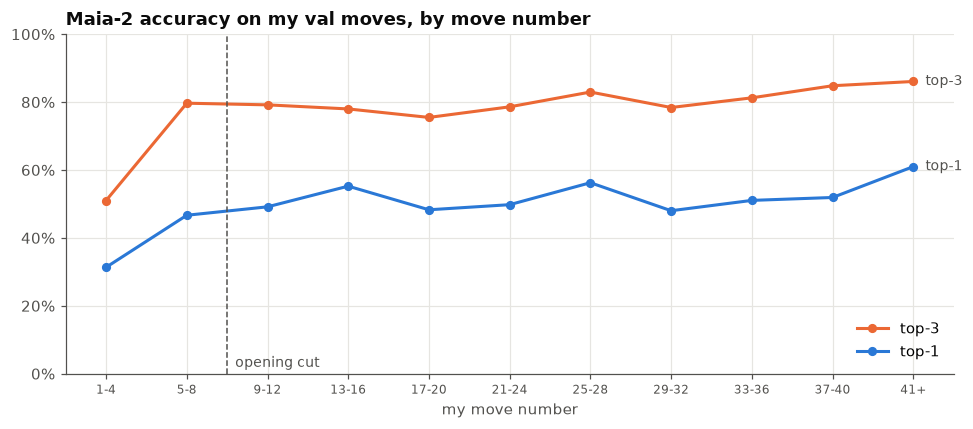

In [8]:
BIN = 4
LAST = 40  # everything after move 40 goes in one final bin
b = np.minimum((preds.move_number - 1) // BIN, LAST // BIN)
by_move = preds.groupby(b).agg(n=("top1", "size"), top1=("top1", "mean"), top3=("top3", "mean"))
labels = [f"{i * BIN + 1}-{(i + 1) * BIN}" if i < LAST // BIN else f"{LAST + 1}+" for i in by_move.index]
x = np.arange(len(by_move))

fig, ax = plt.subplots(figsize=(9, 4))
for col, color, name in [("top3", ORANGE, "top-3"), ("top1", BLUE, "top-1")]:
    ax.plot(x, by_move[col], color=color, lw=2, marker="o", ms=5, label=name)
    ax.annotate(name, (x[-1], by_move[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=MUTED, fontsize=9)
ax.axvline(OPENING_MOVES / BIN - 0.5, color=MUTED, lw=1, ls="--")
ax.text(OPENING_MOVES / BIN - 0.45, 0.02, " opening cut", color=MUTED, fontsize=9, transform=ax.get_xaxis_transform())
ax.set_xticks(x, labels, rotation=0, fontsize=8)
ax.set_xlabel("my move number")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Maia-2 accuracy on my val moves, by move number", loc="left")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
per_game = preds.groupby("game_id").agg(moves=("top1", "size"), top1=("top1", "mean"))
print(f"Top-1 per game: median {per_game.top1.median():.1%}, "
      f"middle half {per_game.top1.quantile(.25):.1%}-{per_game.top1.quantile(.75):.1%}, "
      f"worst {per_game.top1.min():.1%}, best {per_game.top1.max():.1%} "
      f"({len(per_game)} games)")

Top-1 per game: median 50.0%, middle half 44.0%-56.1%, worst 20.8%, best 75.0% (75 games)


## 5. Where Maia gets me wrong

**Confident misses:** positions where Maia gave its top move at least 50% and I played something else. Click **open** to see the position on Lichess.

In [10]:
misses = preds[~preds.top1]
confident = misses[misses.maia_p >= 0.5].sort_values("maia_p", ascending=False)
print(f"{len(misses):,} misses, {len(confident):,} of them with Maia at least 50% sure. "
      f"On {misses.top3.mean():.0%} of misses my move was still in Maia's top 3.")

(confident.head(15)
 .assign(date=lambda d: d.date.str[:10],
         board=lambda d: "https://lichess.org/analysis/" + d.fen.str.replace(" ", "_"))
 [["date", "move_number", "side", "phase", "move_uci", "played_p", "maia_move", "maia_p", "board"]]
 .rename(columns={"move_uci": "I played", "played_p": "p(mine)", "maia_move": "Maia", "maia_p": "p(Maia)"})
 .style.format({"p(mine)": "{:.1%}", "p(Maia)": "{:.1%}",
                "board": lambda url: f'<a href="{url}" target="_blank">open</a>'})
 .hide(axis="index"))

1,242 misses, 301 of them with Maia at least 50% sure. On 54% of misses my move was still in Maia's top 3.


date,move_number,side,phase,I played,p(mine),Maia,p(Maia),board
2026-06-26,8,w,opening,f2g3,1.1%,h2g3,98.7%,open
2026-07-04,5,w,opening,f2g3,1.1%,h2g3,98.6%,open
2026-07-09,43,b,endgame,e3d3,0.6%,d2d1q,97.0%,open
2026-06-27,13,w,middlegame,g2g3,0.5%,f6g8,94.9%,open
2026-07-08,57,w,endgame,a8b8,1.2%,b6b7,93.5%,open
2026-07-03,21,w,middlegame,b4a6,5.2%,b4d5,92.7%,open
2026-07-01,11,b,middlegame,d5e6,0.7%,d5h1,92.1%,open
2026-07-03,25,w,endgame,d1d5,6.3%,a4e8,91.7%,open
2026-06-28,25,b,endgame,a5c5,0.2%,a5b5,91.4%,open
2026-07-02,24,b,endgame,g8h7,9.2%,g8g7,90.8%,open


In [11]:
# Which of Maia's guesses do I most often turn down, and what do I play instead?
(misses.groupby(["phase", "maia_move", "move_uci"]).size().rename("times")
 .sort_values(ascending=False).head(10).reset_index()
 .rename(columns={"maia_move": "Maia expected", "move_uci": "I played"}))

,phase,Maia expected,I played,times
0,opening,g1f3,d2d4,38
1,opening,d1d3,c1f4,27
2,opening,g8f6,c7c6,18
3,opening,c2c3,g1f3,17
4,opening,c2c3,f1d3,14
5,opening,g8f6,d7d6,14
6,opening,d8d7,g8f6,10
7,opening,d8a5,d7d5,7
8,opening,c2c3,e1g1,6
9,opening,d1d2,c1f4,6


## 6. Which Elo should Maia think I am?

Maia-2 was trained on **Lichess** ratings, and chess.com ratings sit on a different scale (roadmap §4, decision 2). This re-runs Maia on the val games with both ratings shifted up by the same amount and checks which shift predicts me best. Shifts under about 150 barely matter, since everything below 1100 is one bucket.

With about 2,500 positions from 75 games, differences under 1–2 points are within noise. If a shift clearly wins here, use that **same** shift when scoring row G on the test games, and write it next to the row. Each shift is one more full pass over val, so set `RUN_ELO_SWEEP = False` to skip it.

In [12]:
RUN_ELO_SWEEP = True
ELO_SHIFTS = [0, 200, 400, 600, 800, 1000]

if RUN_ELO_SWEEP:
    rows = []
    for shift in ELO_SHIFTS:
        s = preds if shift == 0 else score(val, run_maia(val, elo_shift=shift, verbose=False))
        print(f"shift +{shift}: top-1 {s.top1.mean():.1%}")
        rows.append({
            "elo_shift": shift,
            "my median Elo as Maia sees it": int(val.player_elo.median() + shift),
            **{f"top-{k}": s[f"top{k}"].mean() for k in TOP_K},
            "top-1 excl. opening": s.loc[s.move_number > OPENING_MOVES, "top1"].mean(),
            "avg p(my move)": s.played_p.mean(),
        })
    sweep = pd.DataFrame(rows).set_index("elo_shift")
    display(sweep.style.format("{:.1%}", subset=sweep.columns[1:]))

shift +0: top-1 49.5%
shift +200: top-1 49.5%
shift +400: top-1 49.5%
shift +600: top-1 49.4%
shift +800: top-1 48.8%
shift +1000: top-1 48.4%


,my median Elo as Maia sees it,top-1,top-3,top-5,top-1 excl. opening,avg p(my move)
elo_shift,,,,,,
0,1014,49.5%,76.6%,86.9%,52.9%,35.5%
200,1214,49.5%,77.8%,87.8%,53.5%,37.9%
400,1414,49.5%,78.5%,88.5%,53.1%,38.8%
600,1614,49.4%,78.2%,89.1%,52.8%,39.3%
800,1814,48.8%,78.6%,88.7%,52.0%,39.5%
1000,2014,48.4%,77.8%,86.5%,51.7%,39.3%


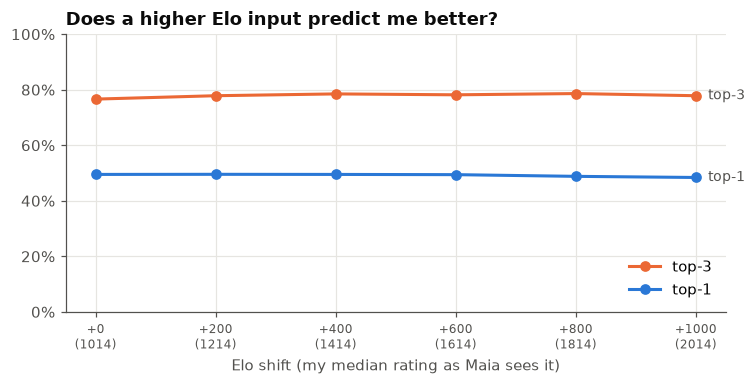

In [13]:
if RUN_ELO_SWEEP:
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for col, color in [("top-3", ORANGE), ("top-1", BLUE)]:
        ax.plot(sweep.index, sweep[col], color=color, lw=2, marker="o", ms=6, label=col)
        ax.annotate(col, (sweep.index[-1], sweep[col].iloc[-1]), xytext=(8, 0),
                    textcoords="offset points", va="center", color=MUTED, fontsize=9)
    ax.set_xticks(sweep.index, [f"+{s}\n({e})" for s, e in
                                zip(sweep.index, sweep["my median Elo as Maia sees it"])], fontsize=8)
    ax.set_xlabel("Elo shift (my median rating as Maia sees it)")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title("Does a higher Elo input predict me better?", loc="left")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

## 7. Summary

A row for the run log in `docs/results.md`. These are **val** numbers, so they don't go in the main table: row G gets scored on the test games.

In [14]:
r = results.loc["all moves (headline)"]
r_ex = results.loc[f"excluding my first {OPENING_MOVES} moves"]
note = f"{int(r.moves):,} moves / {preds.game_id.nunique()} games, Elo as-is"
if RUN_ELO_SWEEP:
    b = sweep["top-1"].idxmax()
    gain = sweep.loc[b, "top-1"] - sweep.loc[0, "top-1"]
    note += (f"; Elo shift: no clear gain on val (best +{b}, {gain * 100:+.1f} pts top-1)" if gain < 0.01
             else f"; Elo shift +{b} adds {gain * 100:+.1f} pts top-1 on val")
print(f"| {date.today()} | Maia-2 rapid off the shelf, {SPLIT} split | {DEVICE_USED} | "
      f"top-1 {r['top-1']:.1%}, top-3 {r['top-3']:.1%}, top-1 excl. opening {r_ex['top-1']:.1%} | {note} |")

| 2026-11-18 | Maia-2 rapid off the shelf, val split | mps:0 | top-1 49.5%, top-3 76.6%, top-1 excl. opening 52.9% | 2,459 moves / 75 games, Elo as-is; Elo shift: no clear gain on val (best +200, +0.0 pts top-1) |
